# 06 · Feature selection

[Guide](../README.md) | [Previous](05_Feature_Engineering.ipynb) | [Next](07_Dimensionality_Reduction.ipynb)

Try keeping or removing columns while retaining the earlier choices.

## Data: training, validation, competition test
`train.csv` contains known answers; `test.csv` does not.
Split `train.csv`: 16,000 rows for learning and comparisons; 4,000 validation rows for the final check.
Comparisons below stay inside the training part. `random_state` repeats the split;
`stratify` keeps similar goal/miss proportions. `X` means inputs; `y` means answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

Train: (20000, 20) Test: (6000, 19)


In [3]:
# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

In [4]:
# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

In [5]:
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, SelectFromModel
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

## Continue from the earlier lessons

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |

Only the current choice changes. `clone` copies settings, not fitted knowledge; `step__setting` points to one pipeline setting.

**Incomplete training rows:** `any(axis=1)` finds a row with at least one blank; `~` keeps the opposite rows. Filter `y` too so answers stay aligned.

In [6]:
def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

**Suspected decoys:** test removing jersey color and referee strictness, not every weak-looking input. The same columns are removed at prediction time.

In [7]:
def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

**Form and technique features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [8]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

**Match context features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [9]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

**Environment features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [10]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

In [11]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

## Prepare each training split separately
Fill numbers with a training mean or median; fill categories with the most common value (**mode**).
Scaling puts numbers on similar scales. Encoding turns category names into numbers (Lesson 04).
No filling values, rankings, or sampling decisions are learned from validation rows.

In [12]:
numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

**Pipeline:** run steps in order. `passthrough` skips a step. `FunctionSampler` applies a row-changing function only during fitting; every prediction-time row is kept. Balancing also runs only during fitting.

In [13]:
pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", "passthrough"),
    ("prepare", preprocess),
    ("selection", "passthrough"),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

## Compare on the same three splits
Train on two groups, score the third, and rotate. **F1** balances precision and recall;
**accuracy** counts all correct answers; **ROC-AUC** measures probability ranking.
**F1 spread** shows how much scores change across the three splits.

In [14]:
# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

| Strategy | What it does | Limit |
|---|---|---|
| Keep all | Do not discard possible signal | Keeps distractions too |
| Tree selection | Keep inputs above the forest's mean importance | Finds nonlinear patterns; rankings can favor detailed inputs |
| Best 10 columns | ANOVA ranks individual class differences | Can miss combinations of inputs |
| L1 selection | Push some linear-model weights to zero | Needs scaling; can miss nonlinear signal |
| Drop suspected decoys | Remove jersey color and referee strictness | Simple and readable; the suspicion may be wrong |
| Drop suspected decoys + L1 | Remove the pair, then select remaining encoded inputs | More compact; may discard useful combinations |

Each ranking is fitted inside a training split, never on its validation answers.
A **decoy** is a distracting input. Here the two named columns are hypotheses to test,
not columns declared useless from the final validation answers. Removing a raw column also removes its one-hot copies.

In [15]:
l1 = LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42)
models = {
    "Keep all columns": clone(pipeline),
    "Tree selection": clone(pipeline).set_params(selection=SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2))),
    "Best 10 columns": clone(pipeline).set_params(selection=SelectKBest(f_classif, k=10)),
    "L1 selection": clone(pipeline).set_params(selection=SelectFromModel(l1)),
    "Drop suspected decoys": clone(pipeline).set_params(decoys=FunctionTransformer(drop_suspected_decoys)),
    "Drop suspected decoys + L1": clone(pipeline).set_params(decoys=FunctionTransformer(drop_suspected_decoys), selection=SelectFromModel(l1)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
5,Drop suspected decoys + L1,0.880,0.002,0.893,0.960
4,Drop suspected decoys,0.880,0.002,0.893,0.960
3,L1 selection,0.878,0.002,0.892,0.960
0,Keep all columns,0.878,0.003,0.891,0.960
1,Tree selection,0.848,0.003,0.864,0.941
2,Best 10 columns,0.786,0.001,0.810,0.868


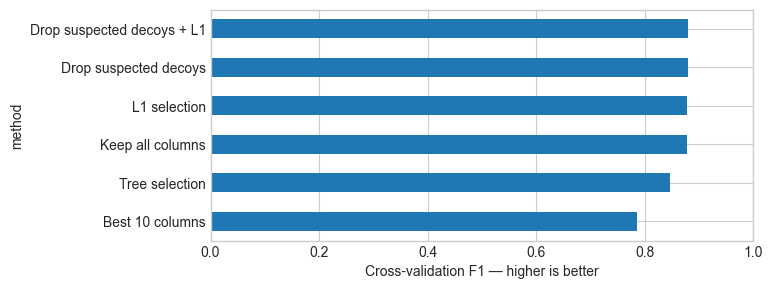

Continue with: Drop suspected decoys + L1


In [16]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

## Find possible distractions visually
**Permutation importance** shuffles one input and measures the F1 loss on unseen example rows.
A larger loss means the model relied more on it. Near-zero importance is a reason to investigate,
not automatic proof that a column is useless. Do not choose columns using this plot and then claim a fresh score on the same rows.
Orange highlights the two suspected decoys. Negative importance means shuffling slightly improved this model's score;
that can be noise or redundancy, not proof of uselessness for every model.

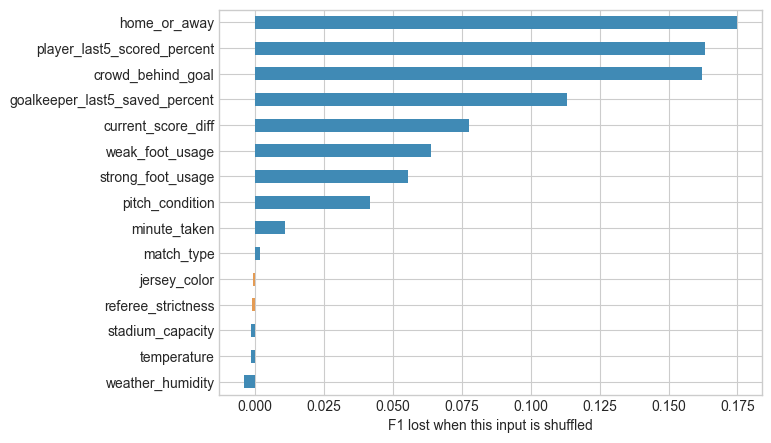

jersey_color         -7.356e-04
referee_strictness   -1.322e-03
Name: F1 lost when shuffled, dtype: float64

In [17]:
from sklearn.inspection import permutation_importance
X_fit, X_example, y_fit, y_example = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
model = clone(pipeline).set_params(model=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2))
model.fit(X_fit, y_fit)
importance = permutation_importance(model, X_example, y_example, scoring="f1", n_repeats=3, random_state=42)
ranking = pd.Series(importance.importances_mean, index=X.columns).sort_values()
colors = ["#e49b54" if name in ["jersey_color", "referee_strictness"] else "#408ab5" for name in ranking.index]
ranking.plot.barh(figsize=(7, 5), color=colors)
plt.xlabel("F1 lost when this input is shuffled")
plt.show()
display(ranking.loc[["jersey_color", "referee_strictness"]].rename("F1 lost when shuffled"))

## Example: which encoded columns remain?
`get_support()` returns a keep/drop mask. The prefixes in the printed names identify the preparation group.

Raw suspected decoys dropped: True


,encoded column,kept
0,numbers__stadium_capacity,True
1,numbers__temperature,True
2,numbers__weather_humidity,True
3,numbers__minute_taken,True
4,numbers__current_score_diff,True
5,numbers__player_last5_scored_percent,True
6,numbers__goalkeeper_last5_saved_percent,False
7,numbers__strong_foot_usage,False
8,numbers__weak_foot_usage,True
9,numbers__skill_gap,True


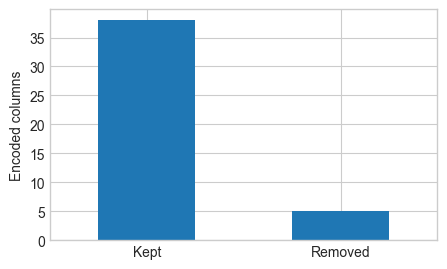

In [18]:
chosen = clone(models[results.iloc[0]["method"]])
chosen.fit(X_fit, y_fit)
names = chosen.named_steps["prepare"].get_feature_names_out()
selector = chosen.named_steps["selection"]
print("Raw suspected decoys dropped:", results.iloc[0]["method"].startswith("Drop suspected decoys"))
keep = np.ones(len(names), dtype=bool)
if selector != "passthrough":
    keep = selector.get_support()
display(pd.DataFrame({"encoded column": names, "kept": keep}))
pd.Series({"Kept": keep.sum(), "Removed": (~keep).sum()}).plot.bar(rot=0, figsize=(5, 3))
plt.ylabel("Encoded columns")
plt.show()

**Why the choice?** Use the score table to decide whether losing columns actually helps.
**Other alternatives:** variance threshold removes constant columns; mutual information looks for broader
input/answer relationships; correlation screening removes redundant measurements; recursive elimination
repeatedly removes weak inputs; Boruta compares inputs with shuffled copies. These require more fitting or assumptions.

## Choice carried into the next lesson

**Selection: Drop suspected decoys + L1.** Drops the two suspected distractions, then removes zero-weight encoded inputs inside each training split.

This is the best tested choice at this stage, not proof that a small score gap is significant or that every combination has been tried.